# INFO 2950 — Phase 2: Chess Openings

Troy Goetz and Nicholas Grabowski

## Part 1: Data Collection and Exploratory Analysis

### Research Question

Do some chess openings perform better at different player ratings, even after accounting for the rating gap between opponents?



### Data Collection and Cleaning



In [1]:
import pandas as pd

# Load the archived raw CSV from our repository; pandas decompresses it.
games = pd.read_csv("https://raw.githubusercontent.com/Toyman123/info2950-project/main/phase2/data/raw/chess_games_raw.csv.gz")

print("Total rows:", len(games))
display(games.head())

Total rows: 64738


,sampled_player,archive_month,game_url,white_username,black_username,white_rating,black_rating,white_result,black_result,rated,rules,time_class,time_control,end_time,opening_url,pgn
0,1richmond,7,https://www.chess.com/game/live/170974137624,Niclear,1Richmond,1345,1339,win,checkmated,True,chess,blitz,300,1782912434,https://www.chess.com/openings/Kings-Pawn-Open...,"[Event ""Live Chess""]\n[Site ""Chess.com""]\n[Dat..."
1,1richmond,7,https://www.chess.com/game/live/170974566586,1Richmond,panduropley240,1331,1343,checkmated,win,True,chess,blitz,300,1782912864,https://www.chess.com/openings/Caro-Kann-Defense,"[Event ""Live Chess""]\n[Site ""Chess.com""]\n[Dat..."
2,1richmond,7,https://www.chess.com/game/live/170974857284,1Richmond,ElisKush11,1323,1355,resigned,win,True,chess,blitz,300,1782913059,https://www.chess.com/openings/French-Defense,"[Event ""Live Chess""]\n[Site ""Chess.com""]\n[Dat..."
3,1richmond,7,https://www.chess.com/game/live/170974987972,ElisKush11,1Richmond,1362,1316,win,resigned,True,chess,blitz,300,1782913139,https://www.chess.com/openings/Kings-Pawn-Open...,"[Event ""Live Chess""]\n[Site ""Chess.com""]\n[Dat..."
4,1richmond,7,https://www.chess.com/game/live/170975038918,1Richmond,ElisKush11,1309,1369,abandoned,win,True,chess,blitz,300,1782913508,https://www.chess.com/openings/French-Defense,"[Event ""Live Chess""]\n[Site ""Chess.com""]\n[Dat..."


Our team collected games through Chess.com's public API. We randomly selected 300 players from the public list of active players who identified their country as the United States, using a fixed random seed of 2950. The team downloaded their available game archives for July, August, and September 2026. Each row in the table represents one game retrieved from a selected player's archive. We saved the original API responses, selected player list, and archive log alongside the CSV.

The data downloaded from Chess.com contains multiple time controls and could contain duplicate games when both opponents were sampled. Our cleaning process keeps rated standard blitz games, removes duplicate game URLs, and checks for missing ratings and opening information. We use White's rating to define the groups and calculate the rating gap as White's rating minus Black's rating. We will group related opening variations into "opening families" and check their coverage across rating groups before selecting our analysis sample.

In [2]:
# Create a separate copy and track how many rows remain.
clean = games.copy()
counts = {"Original rows": len(clean)}

# Keep rated standard blitz games.
clean = clean[
    (clean["rated"] == True)
    & (clean["rules"] == "chess")
    & (clean["time_class"] == "blitz")
].copy()
counts["Rated standard blitz"] = len(clean)

# Remove missing or blank game URLs.
clean = clean.dropna(subset=["game_url"])
clean = clean[clean["game_url"].str.strip() != ""].copy()
counts["With game URL"] = len(clean)

# Remove duplicate games, keeping one row per game URL.
clean = clean.drop_duplicates(subset="game_url").copy()
counts["Unique games"] = len(clean)

# Convert ratings to numbers and remove missing or invalid ratings.
for column in ["white_rating", "black_rating"]:
    clean[column] = pd.to_numeric(clean[column], errors="coerce")

clean = clean.dropna(subset=["white_rating", "black_rating"]).copy()
clean = clean[
    (clean["white_rating"] > 0) & (clean["black_rating"] > 0)
].copy()
counts["With valid ratings"] = len(clean)

# Create rating groups using White's rating during the game.
clean["rating_group"] = pd.cut(
    clean["white_rating"],
    bins=[0, 1000, 1500, 2000, float("inf")],
    labels=["Under 1000", "1000–1499", "1500–1999", "2000+"],
    right=False
)

# Positive values mean White was rated higher than Black.
clean["rating_difference"] = (
    clean["white_rating"] - clean["black_rating"]
)

# Treat blank opening URLs as missing, but retain these games for now.
clean["opening_url"] = clean["opening_url"].replace(
    r"^\s*$", pd.NA, regex=True
)

# Show the cleaning record and rating-group coverage.
display(pd.DataFrame({
    "Cleaning step": list(counts.keys()),
    "Rows remaining": list(counts.values())
}))

print("Games missing opening information:",
      clean["opening_url"].isna().sum())

display(clean["rating_group"].value_counts(sort=False))

# Save an intermediate cleaned dataset.
clean.to_csv("/content/chess_blitz_cleaned.csv", index=False)

Games missing opening information: 0


,Cleaning step,Rows remaining
0,Original rows,64738
1,Rated standard blitz,29385
2,With game URL,29385
3,Unique games,29385
4,With valid ratings,29385


rating_group
Under 1000    20847
1000–1499      6771
1500–1999      1584
2000+           183
Name: count, dtype: int64

We group variations using the names in Chess.com's opening URLs. We preserve the eight original family labels and classify the remaining openings by retaining their names through the first family term: Defense, Opening, Game, Gambit, Attack, or System. Names without one of these terms are retained before any numbered moves, with special handling for Nimzo-Indian and Bogo-Indian labels. These are reproducible label-based groups, not a complete classification of chess positions. Missing labels are marked "Unknown." We retain all identified openings instead of assigning unmatched names to "Other opening."

We also combine alternate family labels: Alapin and Closed Sicilian labels join Sicilian, Giuoco Piano and Pianissimo join Italian, shortened King's Indian and King's Fianchetto labels join their corresponding families, Owens labels join Owen's Defense, and Magnus Queen's Gambit joins Queen's Gambit. The source label "Undefined" is treated as unknown. We extract completed game results from the PGN records and measure outcomes from White's perspective: 1 for a win, 0.5 for a draw, and 0 for a loss. We randomly select 150 games within each of the four rating groups using seed 2950, for 600 games total. Opening classification does not change which games are selected.


In [3]:
# Group every recorded opening by its named family.
# Preserve our existing labels for the eight original families.
families = {
    "Sicilian-Defense": "Sicilian",
    "French-Defense": "French",
    "Caro-Kann-Defense": "Caro-Kann",
    "Scandinavian-Defense": "Scandinavian",
    "Italian-Game": "Italian",
    "Ruy-Lopez": "Ruy Lopez",
    "Queens-Gambit": "Queen's Gambit",
    "London-System": "London"
}

def opening_family(url):
    if pd.isna(url):
        return "Unknown"

    opening = url.rstrip("/").split("/")[-1]

    # Combine alternate labels for the same broad opening family.
    aliases = {
        "Alapin-Sicilian": "Sicilian",
        "Closed-Sicilian": "Sicilian",
        "Giuoco-Piano": "Italian",
        "Giuoco-Pianissimo": "Italian",
        "Kings-Indian": "King's Indian Defense",
        "Kings-Fianchetto": "King's Fianchetto Opening",
        "Owens": "Owen's Defense",
        "Magnus-Queens-Gambit": "Queen's Gambit"
    }
    if opening == "Undefined":
        return "Unknown"
    for prefix, family in aliases.items():
        if opening == prefix or opening.startswith(prefix + "-"):
            return family

    for prefix, family in families.items():
        if opening == prefix or opening.startswith(prefix + "-"):
            return family

    # Special cases whose family name lacks a standard ending.
    for prefix in ["Nimzo-Indian", "Bogo-Indian"]:
        if opening == prefix or opening.startswith(prefix + "-"):
            return prefix + " Defense"

    # Keep the label through its first family term, removing variations.
    # For labels without one, retain the name before numbered moves.
    parts = opening.split("-")
    endings = ["Defense", "Opening", "Game", "Gambit", "Attack", "System"]
    for position, part in enumerate(parts):
        if part in endings:
            parts = parts[:position + 1]
            break
    else:
        for position, part in enumerate(parts):
            if any(character.isdigit() for character in part):
                parts = parts[:position]
                break

    label = " ".join(parts) or "Unknown"
    for word in ["King", "Queen", "Bishop", "Knight", "Alekhine", "Petrov", "Bird"]:
        if label.startswith(word + "s "):
            label = word + "'s " + label[len(word) + 2:]
    return label

clean["opening_family"] = clean["opening_url"].apply(opening_family)

# Read the recorded final result from the game's PGN.
clean["game_result"] = clean["pgn"].str.extract(
    r'\[Result "([^"]+)"\]', expand=False
)

clean["white_score"] = clean["game_result"].map({
    "1-0": 1,
    "1/2-1/2": 0.5,
    "0-1": 0
})

# Remove games without a recognized completed result.
before = len(clean)
clean = clean.dropna(subset=["white_score"]).copy()
print("Games removed for missing/invalid results:", before - len(clean))

# Check opening coverage before sampling.
print("Opening-family counts in the full cleaned dataset:")
display(pd.crosstab(clean["opening_family"], clean["rating_group"]))

# Save the full prepared dataset before selecting a smaller sample.
clean.to_csv("/content/chess_games_prepared.csv", index=False)

# Randomly select 150 games from each rating group.
groups = ["Under 1000", "1000–1499", "1500–1999", "2000+"]
samples = []

for group in groups:
    group_games = clean[clean["rating_group"] == group]

    if len(group_games) < 150:
        raise ValueError(
            f"{group} has only {len(group_games)} games; 150 are needed."
        )

    samples.append(group_games.sample(n=150, random_state=2950))

analysis_games = pd.concat(samples, ignore_index=True)

# Shuffle the final sample so rows are not ordered by rating group.
analysis_games = analysis_games.sample(
    frac=1, random_state=2950
).reset_index(drop=True)

print("Final sample size:", len(analysis_games))
display(analysis_games["rating_group"].value_counts(sort=False))

print("Opening-family counts in the final sample:")
display(pd.crosstab(
    analysis_games["opening_family"],
    analysis_games["rating_group"]
))

analysis_games.to_csv("/content/chess_analysis_sample.csv", index=False)



Games removed for missing/invalid results: 0
Opening-family counts in the full cleaned dataset:
Final sample size: 600
Opening-family counts in the final sample:


rating_group,Under 1000,1000–1499,1500–1999,2000+
opening_family,,,,
Alekhine's Defense,286,24,5,48
Anderssen Opening,63,5,0,0
Benko Gambit,1,0,0,0
Benoni Defense,6,0,3,0
Bird's Opening,61,24,13,0
...,...,...,...,...
Trompowsky Attack,13,3,2,0
Unknown,220,16,4,0
Van Geet Opening,378,16,1,0


rating_group
Under 1000    150
1000–1499     150
1500–1999     150
2000+         150
Name: count, dtype: int64

rating_group,Under 1000,1000–1499,1500–1999,2000+
opening_family,,,,
Alekhine's Defense,0,0,0,37
Benoni Defense,0,0,1,0
Bird's Opening,0,0,3,0
Bishop's Opening,5,5,11,4
Caro-Kann,6,4,3,8
Center Game,3,0,1,0
Colle System,1,1,2,0
Dutch Defense,1,0,2,0
English Opening,0,4,2,2


### Data Description

Each row in our final analysis dataset represents one unique rated standard blitz game played on Chess.com from July through September 2026. The dataset contains 600 games, with 150 games in each of four groups defined by White's rating: under 1000, 1000–1499, 1500–1999, and 2000 or higher. Opponents may be from any country, and a player may appear in several games.

We collected monthly archives through 300 accounts randomly selected from Chess.com's public list of recently active players who identify their country as the United States. The list is a snapshot of available accounts, not a complete historical sampling frame. The downloaded CSV has 64,738 rows; 29,385 unique rated standard blitz games remain after the basic filters. We selected the 600-game sample using seed 2950 after preparing the game results and ratings.

The original columns include the sampled account, archive month, game URL, both usernames and ratings, both result codes, rated status, rules, time category, exact time control, ending timestamp, opening URL, and PGN record. PGN contains recorded moves and game-header information. Derived columns identify the opening family, White's rating group, White-minus-Black rating difference, completed game result, and White's score (win=1, draw=0.5, loss=0). The sample contains 46 identified label-based opening families and two games whose source label is undefined; those two games are retained in the sample but excluded from named-family comparisons.

Chess.com records game activity as part of operating its platform and exposes public records through its Published-Data API. We used Python requests for collection and pandas for organization and cleaning. These are platform records, not survey responses or verified measures of opening knowledge. The raw CSV, player-list snapshot, selected accounts, and archive log are saved so the source population and cleaning process can be inspected. The collection notebook is separate from this submitted cleaning-and-analysis notebook.

Inclusion depends on the player-list snapshot, monthly archive availability, the selected dates, and the filtering rules. More active sampled accounts contribute more games to the original pool, making their games more likely to enter the final sample. Our equal-sized rating groups support comparisons but do not estimate the platform's overall rating distribution. Source ratings refer to the time of each game; country labels come from the accounts used for collection, not verified residency. We did not contact players and do not know whether they expected their public game records to be used for this project.

**Source documentation:** [Chess.com Published-Data API](https://www.chess.com/news/view/published-data-api)

**Raw source data:** [Full collection CSV, losslessly compressed](https://github.com/Toyman123/info2950-project/blob/main/phase2/data/raw/chess_games_raw.csv.gz). The compression preserves every CSV row and field; pandas reads the file directly.

**Collection records:** [Player snapshot, selected accounts, and archive log](https://github.com/Toyman123/info2950-project/blob/main/phase2/data/raw)

**Analysis-ready data:** [The 600-game CSV](https://github.com/Toyman123/info2950-project/blob/main/phase2/data/chess_analysis_600.csv)

**Collection procedure and reproduction instructions:** [Phase 2 project README](https://github.com/Toyman123/info2950-project/blob/main/phase2/README.md)


### Data Limitations

Our sample does not represent all Chess.com games. We collected games only through recently active accounts that identified their country as the United States. Less active players and games involving only accounts outside that list may be underrepresented.

We selected an equal number of games for each rating group. This helps us compare skill levels, but overall statistics from our sample should not be interpreted as estimates for all Chess.com games. Rating groups describe only White's rating, not necessarily both opponents' skill levels.

Some opening families have few games within certain rating groups. Their results may be unstable, and grouping variations into families can hide differences between variations. We will show the number of games behind each comparison.

Players can appear more than once, meaning games are not fully independent. Frequent players' opening preferences and results may influence the patterns we observe. Any statistical analysis we conduct needs to consider this limitation.

We do not randomly assign opening choices. Preparation, familiarity, and playing style may affect both the opening selected and the result. Accounting for rating gaps will not remove all these influences, so our findings describe associations rather than causal effects.

Our opening families are based on Chess.com's URL labels rather than independently reconstructed board positions. Similar positions can receive different labels, and the same family can contain variations with different plans. We document the grouping rules, but they should not be treated as a definitive chess taxonomy. The source label "Undefined" is treated as unknown. Opening labels also do not directly measure aggression or player style.

The sample covers only three months of rated blitz games. Exact blitz time controls can differ, and findings may not extend to rapid, bullet, daily, or over-the-board chess. White's score describes results from one color's perspective: a higher score is not evidence that an opening helps both opponents. Ratings can also be uncertain, and unobserved account sharing or fair-play violations cannot be identified reliably from these fields.

Although the records are public, usernames and game links can identify players and make their game histories easy to find. We will report results at the opening-family and rating-group level, avoid ranking individual players, and avoid interpreting unusual outcomes as evidence of cheating or poor ability. Small-group results could otherwise stigmatize players or lead readers to overgeneralize about lower-rated players. We will frame opening comparisons as uncertain associations within this sample, not prescriptions that a player must follow.


### Exploratory Data Analysis

We examine rating differences, opening coverage, and outcomes in the same 600-game sample. Outcomes use White's perspective. Opening families are selected for the main displays by frequency, not by their results. The plots display the eight most frequent families for readability, while every classified family remains in the dataset. Missing bars in the score plot indicate fewer than 10 games, not zero wins; this display threshold does not guarantee statistical reliability.


,white_rating,black_rating,rating_difference
count,600.00,600.00,600.00
mean,1450.54,1438.20,12.34
std,657.97,654.76,134.04
min,101.00,137.00,-522.00
25%,995.00,971.50,-18.25
50%,1500.00,1455.50,3.00
75%,1989.50,1955.75,27.00
max,3057.00,2739.00,1715.00


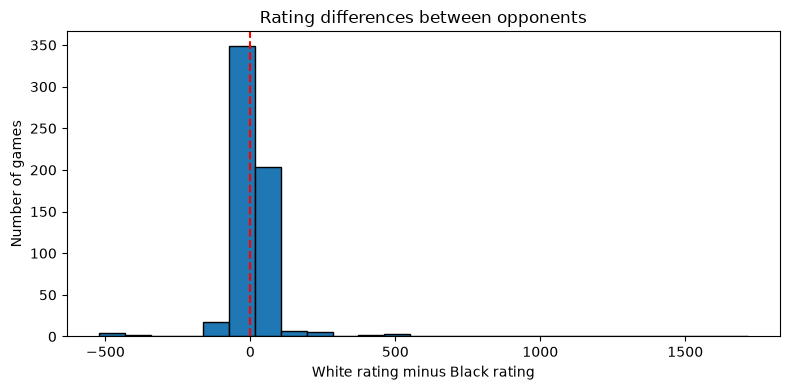

,Games
opening_family,
Sicilian,92
Queen's Pawn Opening,44
Alekhine's Defense,37
French,34
King's Pawn Opening,33
Scandinavian,26
Bishop's Opening,25
Pirc Defense,23
Modern Defense,23


rating_group,Under 1000,1000–1499,1500–1999,2000+
opening_family,,,,
Sicilian,4,15,41,32
Queen's Pawn Opening,25,12,4,3
Alekhine's Defense,0,0,0,37
French,6,14,7,7
King's Pawn Opening,11,15,6,1
Scandinavian,14,3,3,6
Bishop's Opening,5,5,11,4
Pirc Defense,5,5,6,7


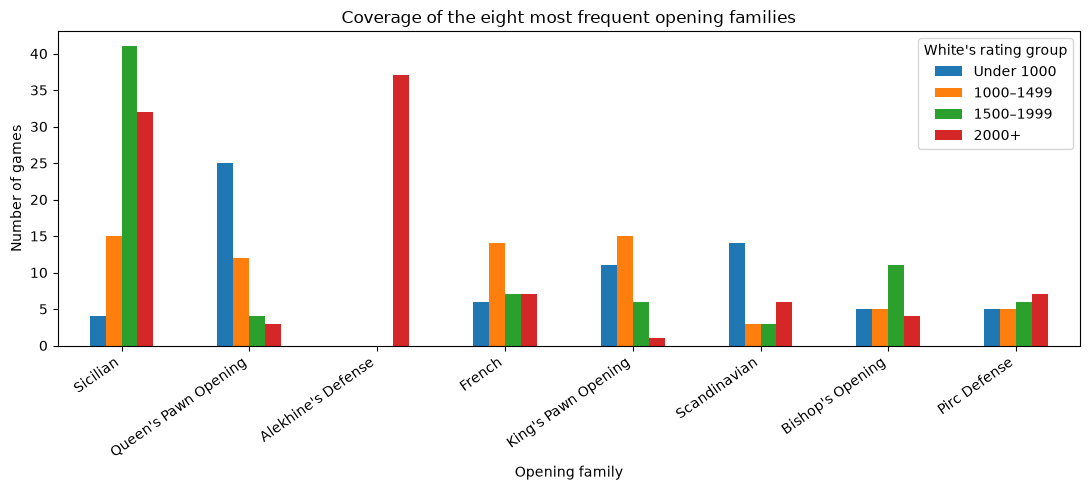

games  average_white_score
opening_family       rating_group                            
Sicilian             Under 1000        4                0.375
                     1000–1499        15                0.333
                     1500–1999        41                0.524
                     2000+            32                0.516
Queen's Pawn Opening Under 1000       25                0.580
                     1000–1499        12                0.333
                     1500–1999         4                0.500
                     2000+             3                0.333
Alekhine's Defense   2000+            37                0.595
French               Under 1000        6                0.500
                     1000–1499        14                0.643
                     1500–1999         7                0.143
                     2000+             7                0.429
King's Pawn Opening  Under 1000       11                0.636
                     1000–1499        15                0.467
                     1500–1999         6                0.083
                     2000+             1                0.000
Scandinavian         Under 1000       14                0.321
                     1000–1499         3                0.667
                     1500–1999         3                0.833
                     2000+             6                0.750
Bishop's Opening     Under 1000        5                0.300
                     1000–1499         5                0.600
                     1500–1999        11                0.500
                     2000+             4                0.500
Pirc Defense         Under 1000        5                0.200
                     1000–1499         5                0.600
                     1500–1999         6                0.667
                     2000+             7                0.286

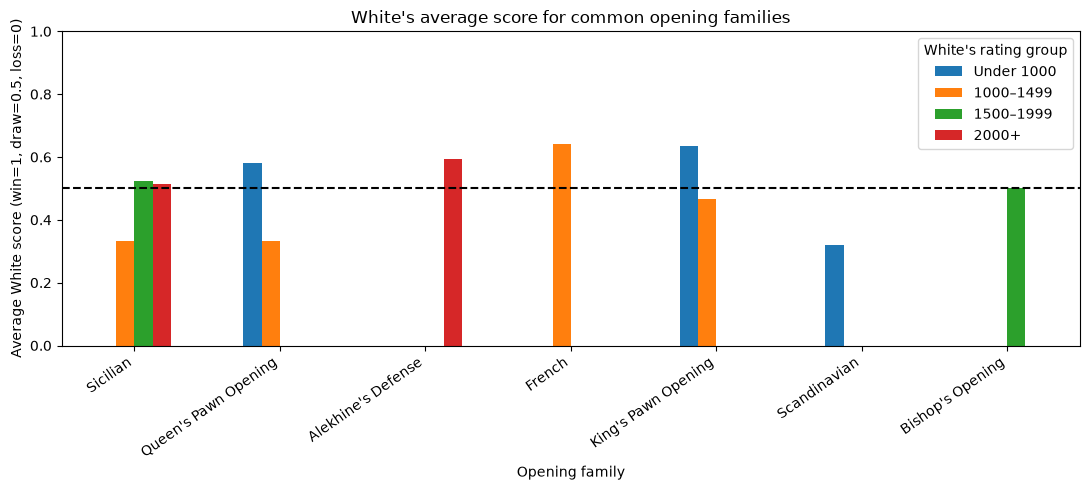

In [4]:
import matplotlib.pyplot as plt

# Inspect the same 600-game sample, using White's perspective.
data = analysis_games.copy()
assert len(data) == 600
display(data[["white_rating", "black_rating", "rating_difference"]].describe().round(2))

data["rating_difference"].plot.hist(bins=25, edgecolor="black", figsize=(8, 4))
plt.axvline(0, color="red", linestyle="--")
plt.title("Rating differences between opponents")
plt.xlabel("White rating minus Black rating")
plt.ylabel("Number of games")
plt.tight_layout()
plt.show()

# Retain every classified family; display the eight most frequent for readability.
named = data[data["opening_family"] != "Unknown"].copy()
family_counts = named["opening_family"].value_counts()
display(family_counts.rename("Games").to_frame())
top_families = family_counts.head(8).index
groups = ["Under 1000", "1000–1499", "1500–1999", "2000+"]
coverage = pd.crosstab(named["opening_family"], named["rating_group"]).reindex(columns=groups, fill_value=0)
display(coverage.loc[top_families])
coverage.loc[top_families].plot.bar(figsize=(11, 5))
plt.title("Coverage of the eight most frequent opening families")
plt.xlabel("Opening family")
plt.ylabel("Number of games")
plt.xticks(rotation=35, ha="right")
plt.legend(title="White's rating group")
plt.tight_layout()
plt.show()

# Show descriptive scores and counts, without fitting the preregistered models.
summary = named.groupby(["opening_family", "rating_group"], observed=True)["white_score"].agg(["count", "mean"]).rename(columns={"count": "games", "mean": "average_white_score"})
display(summary.loc[top_families].round(3))
scores = summary["average_white_score"].unstack("rating_group")
counts = summary["games"].unstack("rating_group")
scores = scores.where(counts >= 10).reindex(index=top_families, columns=groups).dropna(how="all")
if scores.empty:
    print("No displayed opening/rating combinations have at least 10 games.")
else:
    scores.plot.bar(figsize=(11, 5))
    plt.axhline(0.5, color="black", linestyle="--")
    plt.ylim(0, 1)
    plt.title("White's average score for common opening families")
    plt.xlabel("Opening family")
    plt.ylabel("Average White score (win=1, draw=0.5, loss=0)")
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="White's rating group")
    plt.tight_layout()
    plt.show()


### Interpretation of Exploratory Results

The median rating difference is 3 points, with the middle half ranging from -18.25 to 27. Most opponents are closely matched, but a few large rating gaps produce a long right tail. The maximum difference is 1715 points. We retain rating difference in our proposed models and will consider the influence of these unusual games.

The 600 games contain 46 identified opening families. The eight most frequent are Sicilian (92); Queen's Pawn Opening (44); Alekhine's Defense (37); French (34); King's Pawn Opening (33); Scandinavian (26); Bishop's Opening (25); Pirc Defense (23). There are 2 unknown labels, which are excluded from named-family comparisons. The former "Other opening" games now have their own label-based families where identifiable; no games were added or removed by this change.

Families with at least 10 games in two or more rating groups are: King's Pawn Opening, Queen's Pawn Opening, Sicilian. Coverage remains uneven, so equal rating-group sample sizes do not ensure adequate opening-by-rating coverage. We retain the research question but will restrict later model comparisons using the preregistered count-based eligibility rule rather than choosing families by their observed scores.

For the Sicilian, White's average score is 0.333 in 15 games in the 1000–1499 group and 0.524 in 41 games in the 1500–1999 group. This is a descriptive difference, not evidence of a causal effect or an adjusted result. The proposed models will account for rating gaps; no formal preregistered model has been fitted here.


### Questions for Reviewers — Part 1

1. Which opening comparisons have enough coverage to support further analysis?

2. Is our sample of 150 games per rating group sufficient, or should we use more of the cleaned data?

3. Are our opening-family definitions reasonable, and should any variations be separated?

4. Is using White’s rating to define skill groups appropriate, or would the average of both players’ ratings be more useful?

## Part 2: Preregistration of Analyses

We commit to reporting both analyses below regardless of whether they support our hypotheses. These plans follow the descriptive EDA, including the opening regrouping, and precede fitting or testing either proposed regression. We will preserve this version in GitHub so later changes can be distinguished from these plans. Analyses added afterward will be identified as exploratory.


### Preregistration Statement 1

**Hypothesis:** White's expected score differs between Sicilian and French opening-family games after accounting for White's rating group and the rating gap between opponents. The hypothesis is two-sided; we do not commit to either opening having a higher White score. The purpose is to ask whether an opening-family difference remains after adjusting for measured skill, rather than simply confirming that higher-rated opponents tend to do better.

**Proposed analysis:** We will use the games labeled Sicilian or French within the fixed 600-game sample (92 Sicilian and 34 French games after the documented label grouping). We will fit a linear regression predicting White's score (win=1, draw=0.5, loss=0) from an opening indicator, categorical White rating group, and White-minus-Black rating difference divided by 100. French will be the opening reference and 1000–1499 the rating-group reference. The Sicilian coefficient is the adjusted difference in expected White score relative to French. We will assess the two-sided null hypothesis that this coefficient is zero, using a 0.05 significance threshold, and report the coefficient and 95% confidence interval regardless of the result.

We chose these recognizable families because each has at least 30 games in the sample. Their descriptive results have already been explored, but the adjusted regression and significance test have not been run. We will keep the grouping rules and sample fixed for this analysis, check residuals and predictions outside the 0–1 score range, and report limitations from sparse groups and repeated players. Conventional regression intervals assume independent errors and may be too narrow when players repeat; we will flag that assumption and seek mentor feedback before the final analysis. This model is an association model, not a causal comparison.


### Preregistration Statement 2

**Hypothesis:** The association between opening family and White's expected score varies with White's rating, after accounting for the rating gap between opponents.

**Proposed analysis:** We will fit a linear regression predicting White's score from rating difference, White's rating, opening family, and interactions between opening family and White's rating. White's rating and rating difference will be measured in units of 100 rating points. We will include named opening families with at least 30 games spanning at least two rating groups, selecting eligible families by counts rather than outcomes. "Unknown" labels will be excluded from this analysis.

We will compare this model with a model containing the same predictors without the interaction terms. We will report whether the interactions improve model fit and show predicted scores across the observed rating ranges at an equal opponent rating. We will avoid predictions outside each family's observed rating range. If fewer than two families meet our coverage rule, we will report that this analysis could not be supported by the sample.

We will treat opening family as categorical and use Sicilian as its reference category. We will center White's rating at 1500 before dividing by 100, and divide rating difference by 100. We will compare the interaction and main-effects models using a joint F-test of the opening-by-rating interaction terms at a 0.05 significance threshold. This asks whether the relationship between rating and score differs across opening families, complementing the adjusted opening comparison in Statement 1. The descriptive EDA has been inspected, but these models and their significance tests have not been run. We will report repeated-player dependence and sparse coverage as limitations of conventional regression inference and seek mentor guidance on appropriate uncertainty estimates. Findings will not be interpreted causally.


### Questions for Reviewers — Part 2

1. Is linear regression appropriate for a score that takes values of 0, 0.5, and 1?
2. Is the proposed interaction model too complex for our opening-family sample sizes?
3. What method from the course would best account for repeated players?
4. Should we restrict the analysis to one exact blitz time control, or should we account for time control in the model?

5. Is our distinction between the adjusted Sicilian–French comparison and the opening-by-rating interaction analysis clear, and are their regression assumptions reasonable for this sample?
